In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [8]:
data = pd.read_csv("ecg.csv")

In [9]:
data.head()

,-0.11252183,-2.8272038,-3.7738969,-4.3497511,-4.376041,-3.4749863,-2.1814082,-1.8182865,-1.2505219,-0.47749208,...,0.79216787,0.93354122,0.79695779,0.57862066,0.2577399,0.22807718,0.12343082,0.92528624,0.19313742,1.0
0,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
1,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
2,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
3,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0
4,-1.507674,-3.574550,-4.478011,-4.408275,-3.321242,-2.105171,-1.481048,-1.301362,-0.498240,-0.286928,...,1.089068,0.983369,1.014124,0.952629,0.749326,1.007076,1.634990,1.493365,-0.783134,1.0


In [10]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
print("Train Data Shape: ", X_scaled.shape)

Train Data Shape:  (4997, 140)


In [12]:
X_normal = X_scaled[y==0]

In [13]:
trainX, testX = train_test_split(X_normal, test_size = 0.2, random_state = 42)

In [15]:
print("TrainX shape: ", trainX.shape)
print("TestX shape: ", testX.shape)

TrainX shape:  (1663, 140)
TestX shape:  (416, 140)


In [28]:
model = Sequential([
    Input(shape=(140, )),
    Dense(64, activation = "relu"),
    Dense(32, activation = "relu"),
    Dense(64, activation = "relu"),
    Dense(140, activation = "sigmoid")
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,316 (87.17 KB)

 Trainable params: 22,316 (87.17 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "mse",
    metrics = ["mae"]
)

In [30]:
history = model.fit(
    trainX,
    trainX,
    validation_data = (testX, testX),
    batch_size = 256, 
    epochs = 10,
    verbose = 1
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 1.3971 - mae: 0.8661 - val_loss: 1.3420 - val_mae: 0.8440
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.3135 - mae: 0.8329 - val_loss: 1.2369 - val_mae: 0.7997
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1999 - mae: 0.7837 - val_loss: 1.1136 - val_mae: 0.7437
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.0880 - mae: 0.7318 - val_loss: 1.0182 - val_mae: 0.6982
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.0104 - mae: 0.6948 - val_loss: 0.9606 - val_mae: 0.6685
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9588 - mae: 0.6659 - val_loss: 0.9230 - val_mae: 0.6429
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9250 - mae: 0.6428 - val_loss: 0.9005 - val_mae: 0.6272
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9033 - mae: 0.6279 - val_loss: 0.8853 - val_mae: 0.6158
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.8890 - mae: 0.6167 - 

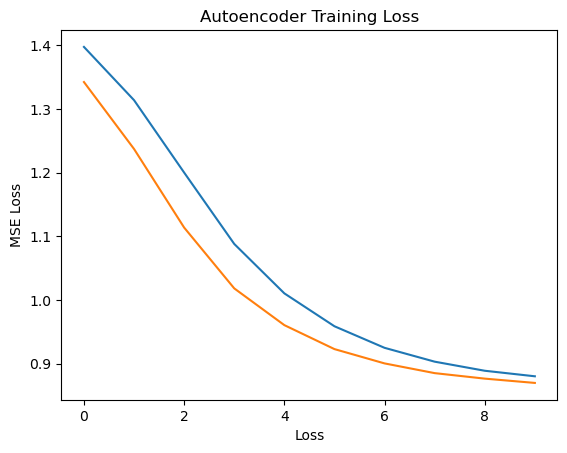

In [31]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label = "Validation Loss")
plt.xlabel("Loss")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.show()

In [32]:
train_reconstruct = model.predict(X_scaled, verbose = 0)
train_error = np.mean(np.square(X_scaled-train_reconstruct), axis = 1)

In [33]:
print("Reconstruction Error: ", train_error)

Reconstruction Error:  [0.91417166 0.68329519 0.61944772 ... 0.3180347  1.31185861 0.20223659]


In [34]:
threshold = np.percentile(train_error, 95)
print("Threshold : ", threshold)

Threshold :  2.43896841345393


In [35]:
test_reconstruct = model.predict(testX, verbose = 0)
test_error = np.mean(np.square(testX-test_reconstruct), axis = 1)

In [44]:
y_pred = (train_error>threshold).astype(int)

In [45]:
print("Precicted Classes: ", y_pred[:10])

Precicted Classes:  [0 0 0 0 0 0 0 0 0 0]


In [46]:
print("Number of anomalies detected: ", y_pred.sum())

Number of anomalies detected:  250


In [47]:
print("Confusion Matrix: ", confusion_matrix(y, y_pred))
print("Classification Report: ", classification_report(y, y_pred))

Confusion Matrix:  [[1934  145]
 [2813  105]]
Classification Report:                precision    recall  f1-score   support

         0.0       0.41      0.93      0.57      2079
         1.0       0.42      0.04      0.07      2918

    accuracy                           0.41      4997
   macro avg       0.41      0.48      0.32      4997
weighted avg       0.41      0.41      0.27      4997

